# Gradient Boosting (regression)

Builds an additive model `F(x) = mean(y) + lr * sum(tree_m(x))`. Each shallow regression tree is fit to the residuals `y - F(x)` of the ensemble so far, which is the negative gradient of squared error. Small `learning_rate` with many trees generalizes best.

Unlike Random Forest (parallel, variance-reducing), trees here are sequential and bias-reducing.

## Usage

```python
# (the class is defined in the Implementation section below)

model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class _RegressionTree:
    """Small CART regression tree: splits minimize squared error, leaves predict the mean."""

    def __init__(self, max_depth=3, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def fit(self, X, y):
        self.root = self._grow(X, y, depth=0)
        return self

    def predict(self, X):
        return self._predict(self.root, X)

    def _grow(self, X, y, depth):
        if depth >= self.max_depth or len(y) < self.min_samples_split:
            return y.mean()

        n, total = len(y), y.sum()
        best_gain, best_feature, best_threshold = 1e-12, None, None
        for f in range(X.shape[1]):
            order = np.argsort(X[:, f])
            xs, ys = X[order, f], y[order]
            left_sum = np.cumsum(ys)[:-1]
            left_n = np.arange(1, n)
            # variance reduction, up to a constant: sum_l^2/n_l + sum_r^2/n_r - sum^2/n
            gain = left_sum**2 / left_n + (total - left_sum) ** 2 / (n - left_n) - total**2 / n
            gain = np.where(xs[1:] != xs[:-1], gain, -np.inf)  # can't split between equal values
            i = gain.argmax()
            if gain[i] > best_gain:
                best_gain, best_feature, best_threshold = gain[i], f, (xs[i] + xs[i + 1]) / 2

        if best_feature is None:
            return y.mean()

        mask = X[:, best_feature] <= best_threshold
        return (
            best_feature,
            best_threshold,
            self._grow(X[mask], y[mask], depth + 1),
            self._grow(X[~mask], y[~mask], depth + 1),
        )

    def _predict(self, node, X):
        if not isinstance(node, tuple):
            return np.full(len(X), node)
        feature, threshold, left, right = node
        mask = X[:, feature] <= threshold
        out = np.empty(len(X))
        out[mask] = self._predict(left, X[mask])
        out[~mask] = self._predict(right, X[~mask])
        return out


class GradientBoostingRegressor:
    """Squared-error gradient boosting: each tree fits the residuals of the ensemble so far."""

    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, min_samples_split=2):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.init_ = None
        self.trees = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.init_ = y.mean()
        pred = np.full(len(y), self.init_)
        self.trees = []
        for _ in range(self.n_estimators):
            residual = y - pred  # negative gradient of 1/2 * squared error
            tree = _RegressionTree(self.max_depth, self.min_samples_split).fit(X, residual)
            pred += self.learning_rate * tree.predict(X)
            self.trees.append(tree)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        pred = np.full(len(X), self.init_)
        for tree in self.trees:
            pred += self.learning_rate * tree.predict(X)
        return pred

## See it work

### 1. Each tree fits what the ensemble still gets wrong

Start from the mean. Compute the residuals `y − prediction` (for squared loss these are the negative gradients), fit a small tree to them, and add a *fraction* (`learning_rate`) of it to the prediction. Repeat. Top row: the ensemble after `k` trees. Bottom row: the remaining residuals, which shrink toward noise.

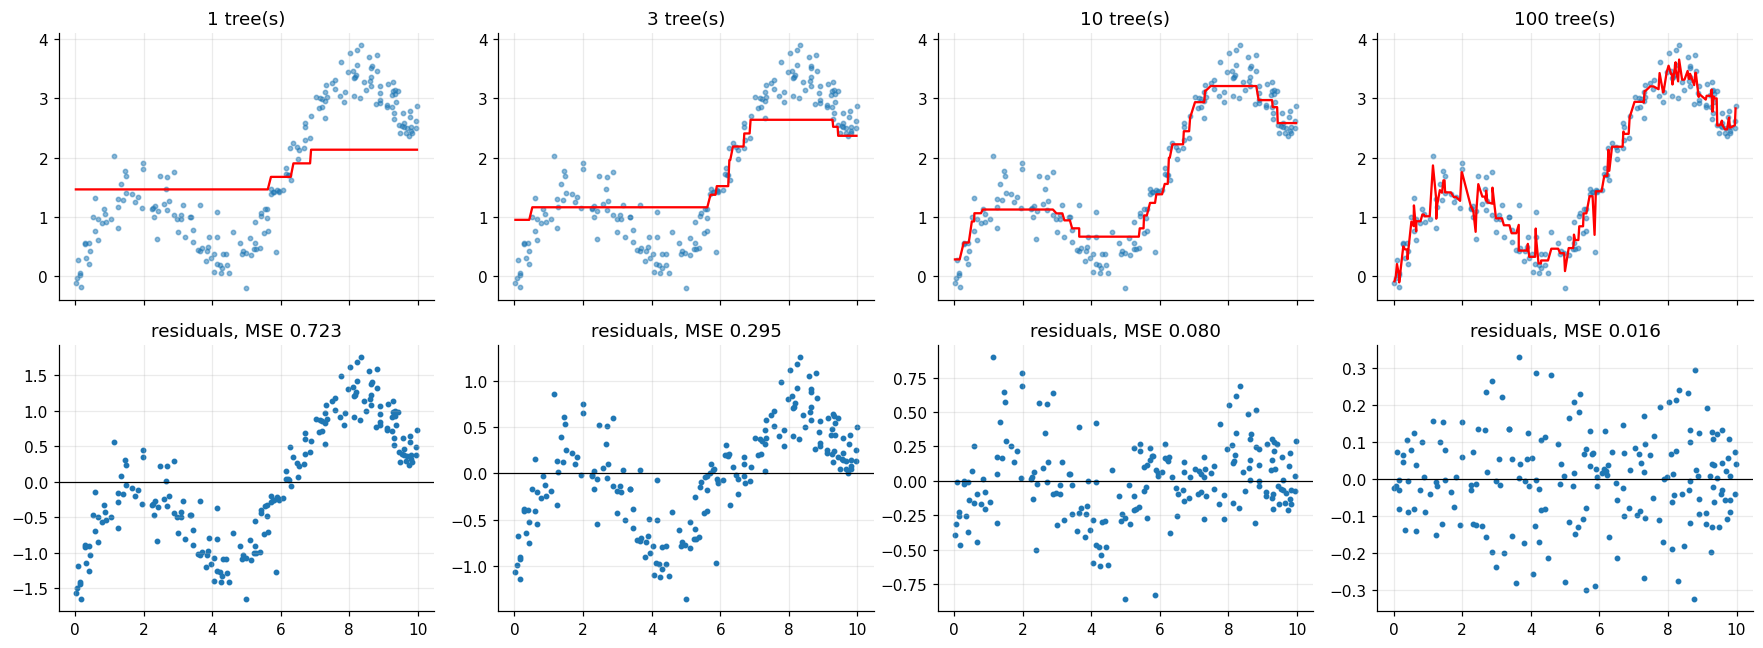

In [3]:
def staged(m, X):
    """Prediction of the ensemble after 1, 2, ... trees."""
    pred, out = np.full(len(X), m.init_), []
    for t in m.trees:
        pred = pred + m.learning_rate * t.predict(X); out.append(pred.copy())
    return out

rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 10, 200)); y = np.sin(x) + 0.3 * x + rng.normal(scale=0.25, size=200)
m = GradientBoostingRegressor(n_estimators=100, learning_rate=0.3, max_depth=2).fit(x[:, None], y)
stages = staged(m, x[:, None])
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for j, k in enumerate([1, 3, 10, 100]):
    axes[0, j].scatter(x, y, s=8, alpha=0.5); axes[0, j].plot(x, stages[k - 1], "r"); axes[0, j].set_title(f"{k} tree(s)")
    axes[1, j].scatter(x, y - stages[k - 1], s=8); axes[1, j].axhline(0, color="k", lw=0.8); axes[1, j].set_title(f"residuals, MSE {np.mean((y - stages[k - 1]) ** 2):.3f}")
plt.tight_layout(); plt.show()

### 2. Learning rate vs number of trees

A small learning rate takes smaller steps, so it needs more trees but usually generalises better; a large one is fast and then starts to overfit. Test error vs ensemble size for three learning rates:

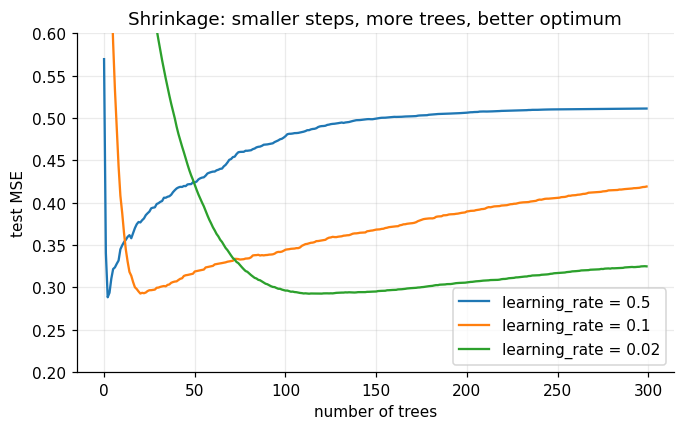

In [4]:
x2 = rng.uniform(0, 10, 600); y2 = np.sin(x2) + 0.3 * x2 + rng.normal(scale=0.5, size=600)
xtr, ytr, xte, yte = x2[:200], y2[:200], x2[200:], y2[200:]
plt.figure(figsize=(7, 4))
for lr in (0.5, 0.1, 0.02):
    mm = GradientBoostingRegressor(n_estimators=300, learning_rate=lr, max_depth=3).fit(xtr[:, None], ytr)
    plt.plot([np.mean((p - yte) ** 2) for p in staged(mm, xte[:, None])], label=f"learning_rate = {lr}")
plt.xlabel("number of trees"); plt.ylabel("test MSE"); plt.ylim(0.2, 0.6); plt.legend(); plt.title("Shrinkage: smaller steps, more trees, better optimum"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
from sklearn.datasets import make_friedman1
from sklearn.ensemble import GradientBoostingRegressor as SklearnGBR
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

X, y = make_friedman1(n_samples=500, noise=1.0, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

ours = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3).fit(X_train, y_train)
theirs = SklearnGBR(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=0).fit(X_train, y_train)

mse_ours = mean_squared_error(y_test, ours.predict(X_test))
mse_theirs = mean_squared_error(y_test, theirs.predict(X_test))
print("friedman1 test MSE: ours=%.4f sklearn=%.4f" % (mse_ours, mse_theirs))
assert abs(mse_ours - mse_theirs) / mse_theirs < 0.15

friedman1 test MSE: ours=2.9520 sklearn=2.9355


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def test_tree_splits_step_function():
    X = np.array([[1.0], [2.0], [3.0], [10.0], [11.0], [12.0]])
    y = np.array([5.0, 5.0, 5.0, 20.0, 20.0, 20.0])
    preds = _RegressionTree(max_depth=1).fit(X, y).predict(X)
    assert np.allclose(preds, y)


def test_fits_sine_and_more_trees_help():
    rng = np.random.default_rng(0)
    X = rng.uniform(0, 6, size=(300, 1))
    y = np.sin(X[:, 0]) + rng.normal(scale=0.05, size=300)

    mse = lambda m: np.mean((m.predict(X) - y) ** 2)
    few = GradientBoostingRegressor(n_estimators=5).fit(X, y)
    many = GradientBoostingRegressor(n_estimators=100).fit(X, y)
    assert mse(many) < mse(few)
    assert mse(many) < 0.01


def test_zero_trees_predicts_mean():
    X = np.arange(10.0).reshape(-1, 1)
    y = np.arange(10.0)
    model = GradientBoostingRegressor(n_estimators=0).fit(X, y)
    assert np.allclose(model.predict(X), y.mean())

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_tree_splits_step_function
PASS test_fits_sine_and_more_trees_help
PASS test_zero_trees_predicts_mean

all 3 tests passed


## Takeaways

- **Use it** as one of the strongest general-purpose models for tabular data. Gradient boosting is gradient descent in *function space*: each tree is a step along the negative gradient of the loss.
- **For squared loss** the negative gradient is just the residual; for other losses (log-loss, absolute) you fit the tree to that loss's gradient (`23_gradient_boosting_classifier`).
- **Knobs:** `n_estimators` × `learning_rate` (trade off), `max_depth` (interaction order, 3-6 typical), subsampling and regularisation (`24_xgboost`). Early stopping on a validation set is standard.
- **Interview line:** *"Fit a shallow tree to the residuals, add it scaled by a learning rate, repeat; it is functional gradient descent."*